# 06. 장치에 인공신경망 넣기 — 환경 부담 점수로 신호등 켜기

## 왜 상태 분류 신경망을 그대로 넣지 않았나
03번의 상태 분류 MLP는 11/14 오후 2시간(라벨 9개) 동안의 조건(온도 23.05~23.58℃, 조도 약 200lx)만 보고 배웠다. 그 범위를 조금만 벗어나도(밤 기온 22℃, 불 끈 방 등) 출력이 0이나 1로 쏠려 신호등이 계속 한 색으로 켜졌다(아래 1번에서 확인). 그래서 장치에는

1. **CO₂ 10분 예측 신경망(02번)** — 7일치(5,551개 시점)로 학습, 처음 보는 날로 검증
2. **소리 AI 오토인코더(05번)** — 24시간 소리로 '평소 소리'를 학습, 처음 듣는 소리 실험으로 검증

을 넣고, 두 AI의 출력과 법정 기준이 있는 조명·온습도를 **0~1 부담으로 바꿔 합치는 공식**으로 환경 부담 점수를 만든다.

| 항목 | 0점 → 1점 | 근거 |
|---|---|---|
| CO₂ (**10분 뒤 예측값**) | 1000 → 2500 ppm | 학교보건법 1000ppm, 04번 최적 확률 경계 약 2100ppm |
| 소음 (**소리 AI 복원 오차**, 최근 10분 평균) | 평소 소리 90% 수준 → 그 100배 (로그 눈금) | 05번 오토인코더 |
| 조명 (최근 10초) | 기준(luxLow) 이상 0, 미만이면 0.5부터 어두울수록 1 | 학교보건법 300lx(웹앱에서 조정) |
| 온도·습도 | 18~28℃, 30~80% 안이면 0, 벗어나면 0.5부터 | 학교보건법 |

**합치는 방법:** 점수 = 1 − (1−w·s_CO₂)(1−s_소음)(1−s_조명)(1−s_온습도). 한 요인만 커도 점수가 오르고, 여러 요인이 조금씩 나쁘면 함께 쌓여 오른다('여러 요인 복합'). CO₂ 비중 **w는 사람이 남긴 라벨로 정한다**(아래 5번).

**단계:** 점수(약 3분 지수이동평균) < 0.4 초록(양호), ≥ 0.4 노랑(주의), ≥ 0.7 빨강(경고). CO₂만 보면 10분 뒤 예측 1600ppm에서 노랑, 2050ppm에서 빨강이다.

In [1]:
import os, numpy as np, pandas as pd, joblib, matplotlib.pyplot as plt, matplotlib.dates as md
from sklearn.metrics import roc_auc_score
from common import *

## 1) 상태 분류 신경망이 학습 범위 밖에서 쏠리는지 확인

In [2]:
rec = pd.read_csv(f"{PROC}/records_clean.csv", encoding="utf-8-sig")
rec["t"] = pd.to_datetime(rec["time"]).dt.tz_convert("Asia/Seoul").dt.tz_localize(None)   # 한국 시간
st = joblib.load(f"{PROC}/state_mlp8.joblib")
X8 = rec[st["feats"]].fillna(rec[st["feats"]].mean())
rec["cls_score"] = 1 - st["model"].predict_proba(st["scaler"].transform(X8))[:, 0]
lab_mask = rec["state_label"].notna()
print(f"라벨 구간 밖(학습하지 않은 시간)에서 상태 분류 신경망 점수가 0.7 이상(빨강)인 비율: {(rec.loc[~lab_mask,'cls_score']>=.7).mean()*100:.0f}%")

라벨 구간 밖(학습하지 않은 시간)에서 상태 분류 신경망 점수가 0.7 이상(빨강)인 비율: 98%


## 2) 장치와 같은 계산으로 CO₂ 10분 뒤 예측값 만들기
장치는 10초 기록 6개를 평균해 1분 값을 만들고, 직전 3분 중앙값으로 다듬은 뒤 1·2·5·10분 변화량을 02번 신경망에 넣는다(창문 센서가 없으면 창문 값은 0).

In [3]:
co2m = joblib.load(f"{PROC}/co2_mlp.joblib")
def co2_pred_series(df):
    out = pd.Series(np.nan, index=df.index)
    for _, g in df.groupby("seg"):
        m1 = g.set_index("t")["co2"].resample("1min").mean()
        c = m1.rolling(3, min_periods=2).median()
        F = pd.DataFrame({f"d{k}": c - c.shift(k) for k in (1, 2, 5, 10)}); F["win"] = 0.0; F["dwin"] = 0.0
        ok = F.notna().all(axis=1)
        pred = pd.Series(np.nan, index=F.index)
        pred[ok] = c[ok] + co2m["model"].predict(co2m["scaler"].transform(F.loc[ok, co2m["feats"]]))
        out.loc[g.index] = pred.reindex(g["t"].dt.floor("1min")).to_numpy()
    return out
rec["co2_pred10"] = co2_pred_series(rec).fillna(rec["co2"])
snd = pd.read_csv(f"{PROC}/sound_ai.csv", encoding="utf-8-sig")
rec = rec.merge(snd[["time", "s_snd_ai"]], on="time", how="left")
rec["s_snd_ai10"] = rec.groupby("seg")["s_snd_ai"].transform(lambda s: s.rolling(60, min_periods=1).mean())   # 장치처럼 최근 10분 평균

## 3) 환경 부담 점수 계산 (펌웨어와 같은 식)

In [4]:
def ramp(x, a, b): return np.clip((x - a) / (b - a), 0, 1)
LUX_LOW, TMIN, TMAX, HMIN, HMAX = 100, 18, 28, 30, 80
W_CO2 = 1.0          # 5번에서 라벨로 다시 정함
def env_score(df, w_co2=None):
    w_co2 = W_CO2 if w_co2 is None else w_co2
    s_co2 = w_co2 * ramp(df["co2_pred10"], 1000, 2500)
    s_snd = df["s_snd_ai10"]                          # 소리 AI (오토인코더 복원 오차 → 부담)
    lux = df["lux"]                                   # 장치와 같이 최근 10초 조도 사용
    s_lux = np.where(lux >= LUX_LOW, 0, 0.5 + 0.5 * np.clip((LUX_LOW - lux) / LUX_LOW, 0, 1))
    t, h = df["f_temp"], df["f_hum"]
    s_t = np.where((t >= TMIN) & (t <= TMAX), 0, 0.5 + 0.5 * np.clip(np.maximum(TMIN - t, t - TMAX) / 3, 0, 1))
    s_h = np.where((h >= HMIN) & (h <= HMAX), 0, 0.5 + 0.5 * np.clip(np.maximum(HMIN - h, h - HMAX) / 15, 0, 1))
    parts = pd.DataFrame({"CO₂(예측)": s_co2, "소음": s_snd, "조명": s_lux, "온습도": np.maximum(s_t, s_h)}, index=df.index).fillna(0)
    return 1 - (1 - parts).prod(axis=1), parts
rec["score_raw"], parts = env_score(rec)
rec["score"] = rec.groupby("seg")["score_raw"].transform(lambda s: s.ewm(alpha=0.05, adjust=False).mean())
rec["level"] = np.select([rec.score >= .7, rec.score >= .4], [2, 1], 0)
rec["cause"] = parts.idxmax(axis=1).where(rec.level > 0, "")

## 4) 결과: 하루 동안 신호등이 어떻게 켜졌을까

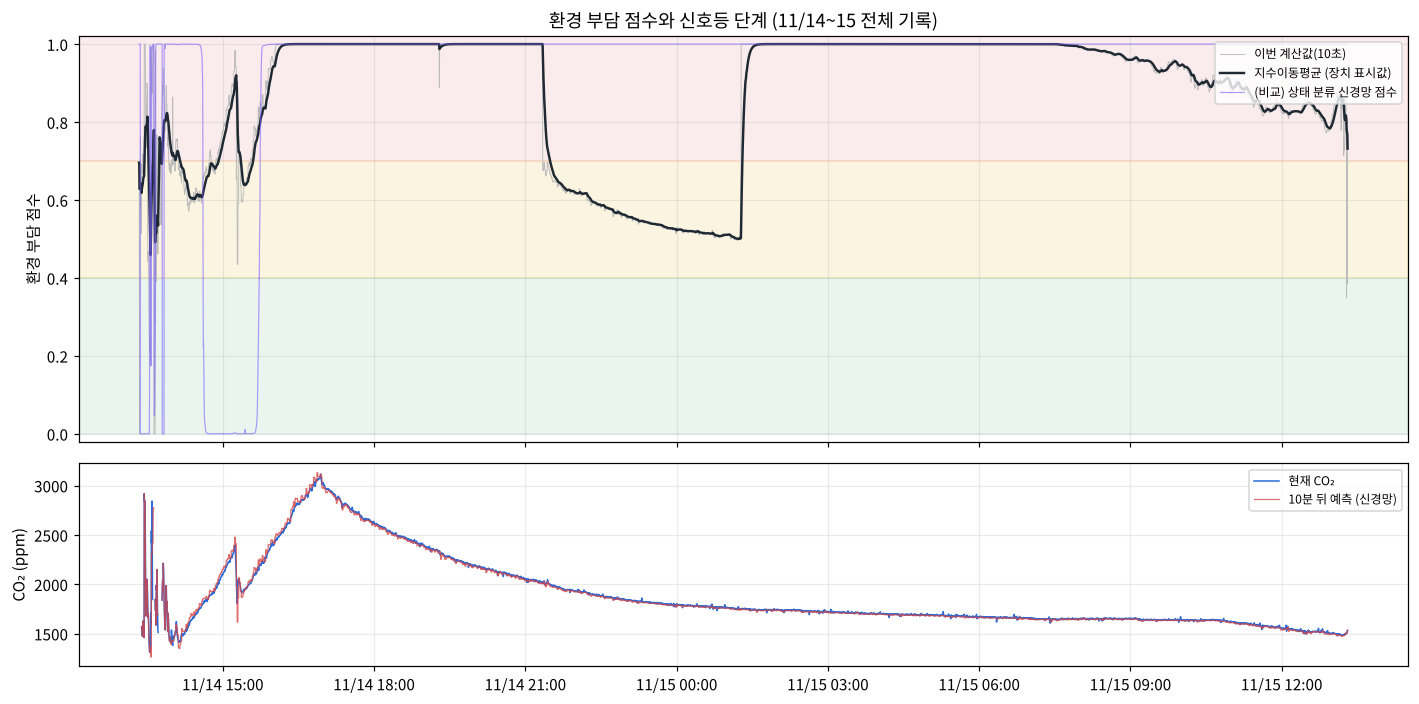

t
11/14 13시    초록 0% 노랑 44% 빨강 56%
11/14 15시    초록 0% 노랑 24% 빨강 76%
11/14 17시    초록 0% 노랑 0% 빨강 100%
11/14 19시    초록 0% 노랑 0% 빨강 100%
11/14 21시    초록 0% 노랑 51% 빨강 49%
11/14 23시    초록 0% 노랑 100% 빨강 0%
11/15 01시    초록 0% 노랑 31% 빨강 69%
11/15 03시    초록 0% 노랑 0% 빨강 100%
11/15 05시    초록 0% 노랑 0% 빨강 100%
11/15 07시    초록 0% 노랑 0% 빨강 100%
11/15 09시    초록 0% 노랑 0% 빨강 100%
11/15 11시    초록 0% 노랑 0% 빨강 100%
11/15 13시    초록 0% 노랑 0% 빨강 100%

노랑·빨강일 때 가장 큰 원인: {'조명': 5422, 'CO₂(예측)': 2962, '소음': 184}


In [5]:
fig, ax = plt.subplots(2, 1, figsize=(13, 6.5), sharex=True, gridspec_kw={"height_ratios": [2, 1]})
ax[0].plot(rec.t, rec.score_raw, color="#bbb", lw=.6, label="이번 계산값(10초)")
ax[0].plot(rec.t, rec.score, color="#1f2933", lw=1.6, label="지수이동평균 (장치 표시값)")
ax[0].plot(rec.t, rec.cls_score, color="#7b61ff", lw=.8, alpha=.6, label="(비교) 상태 분류 신경망 점수")
ax[0].axhspan(0, .4, color="#2e9e5b", alpha=.10); ax[0].axhspan(.4, .7, color="#e0a800", alpha=.12); ax[0].axhspan(.7, 1.02, color="#d64545", alpha=.10)
ax[0].set_ylabel("환경 부담 점수"); ax[0].legend(fontsize=8, loc="upper right"); ax[0].grid(alpha=.25); ax[0].set_ylim(-.02, 1.02)
ax[1].plot(rec.t, rec.co2, color="#2b6cd8", lw=1, label="현재 CO₂"); ax[1].plot(rec.t, rec.co2_pred10, color="#d64545", lw=.8, alpha=.8, label="10분 뒤 예측 (신경망)")
ax[1].set_ylabel("CO₂ (ppm)"); ax[1].legend(fontsize=8); ax[1].grid(alpha=.25)
ax[1].xaxis.set_major_formatter(md.DateFormatter("%m/%d %H:%M"))
ax[0].set_title("환경 부담 점수와 신호등 단계 (11/14~15 전체 기록)")
plt.tight_layout(); plt.savefig(f"{RES}/06_env_score_timeline.png", dpi=150); plt.show()

share = rec.groupby(rec.t.dt.strftime("%m/%d %H시"))["level"].agg(lambda s: f"초록 {(s==0).mean()*100:.0f}% 노랑 {(s==1).mean()*100:.0f}% 빨강 {(s==2).mean()*100:.0f}%")
print(share.iloc[::2].to_string())
print("\n노랑·빨강일 때 가장 큰 원인:", rec.loc[rec.level > 0, "cause"].value_counts().to_dict())

## 5) 사람이 남긴 라벨로 CO₂ 비중 정하기
같은 비중(w = 1)으로 합치면 라벨 구간에서 점수와 실제 상태가 맞지 않았다. 이 2시간 동안 CO₂는 1500 → 2400ppm으로 계속 올랐지만 집중도는 오히려 높아졌기 때문이다. 짧은 시간에는 CO₂가 높아도 바로 산만해지지 않는다는 뜻이다.
그래서 CO₂ 비중 w를 0~1에서 0.05 간격으로 바꿔 가며 라벨과 가장 잘 맞는 값을 찾는다.
- 정직한 평가를 위해 **라벨 하나를 빼고 나머지 8개로 w를 고른 뒤, 뺀 라벨로 평가**하는 것을 9번 반복한 결과도 함께 낸다.

라벨 하나씩 빼고 고른 w: [np.float64(0.45), np.float64(0.45), np.float64(0.5), np.float64(0.35), np.float64(0.4), np.float64(0.45), np.float64(0.5), np.float64(0.45), np.float64(0.0)] → 중앙값 0.45
AUC — 같은 비중(w=1) 0.462 → w=0.45 0.908 (비중을 정할 때 쓴 라벨로 잰 값)
라벨 하나씩 빼고 정한 뒤 뺀 라벨로 잰 AUC: 0.597 (처음 보는 라벨 기준)


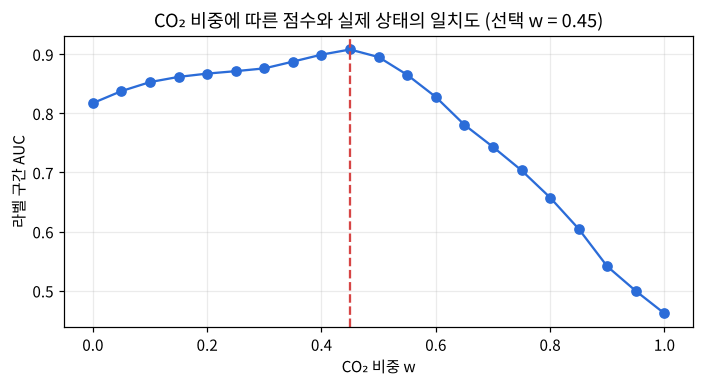

level          노랑    초록
state_label            
산만           0.89  0.11
최적           0.25  0.75

하루 전체 신호등 비율: {'초록': 20.0, '노랑': 12.0, '빨강': 68.0}


In [6]:
def scored(w):
    sc_, _ = env_score(rec, w)
    return sc_.groupby(rec["seg"]).transform(lambda s: s.ewm(alpha=0.05, adjust=False).mean())
WS = np.round(np.arange(0, 1.0001, 0.05), 2)
SC = {w: scored(w) for w in WS}
yb = (rec["state_label"] == 2); g = rec["group"]
auc_all = pd.Series({w: roc_auc_score(yb[lab_mask], SC[w][lab_mask]) for w in WS})
oof = pd.Series(np.nan, index=rec.index); picks = []
for k in sorted(g[lab_mask].unique()):
    trm, tem = lab_mask & (g != k), lab_mask & (g == k)
    wk = max(WS, key=lambda w: roc_auc_score(yb[trm], SC[w][trm])); picks.append(wk); oof[tem] = SC[wk][tem]
W_CO2 = float(np.median(picks))
print("라벨 하나씩 빼고 고른 w:", picks, "→ 중앙값", W_CO2)
print(f"AUC — 같은 비중(w=1) {auc_all[1.0]:.3f} → w={W_CO2} {auc_all[W_CO2]:.3f} (비중을 정할 때 쓴 라벨로 잰 값)")
print(f"라벨 하나씩 빼고 정한 뒤 뺀 라벨로 잰 AUC: {roc_auc_score(yb[lab_mask], oof[lab_mask]):.3f} (처음 보는 라벨 기준)")
fig, a = plt.subplots(figsize=(6.5, 3.6))
a.plot(auc_all.index, auc_all.values, "o-", color="#2b6cd8"); a.axvline(W_CO2, ls="--", color="#d64545")
a.set_xlabel("CO₂ 비중 w"); a.set_ylabel("라벨 구간 AUC"); a.set_title(f"CO₂ 비중에 따른 점수와 실제 상태의 일치도 (선택 w = {W_CO2})"); a.grid(alpha=.25)
plt.tight_layout(); plt.savefig(f"{RES}/06_co2_weight.png", dpi=150); plt.show()

# 정한 비중으로 다시 계산
rec["score_raw"], parts = env_score(rec)
rec["score"] = rec.groupby("seg")["score_raw"].transform(lambda s: s.ewm(alpha=0.05, adjust=False).mean())
rec["level"] = np.select([rec.score >= .7, rec.score >= .4], [2, 1], 0)
rec["cause"] = parts.idxmax(axis=1).where(rec.level > 0, "")
L = rec[lab_mask]; y = L["state_label"].astype(int)
print(pd.crosstab(y.map(STATE_KO), L.level.map({0: "초록", 1: "노랑", 2: "빨강"}), normalize="index").round(2).to_string())
print("\n하루 전체 신호등 비율:", (rec.level.value_counts(normalize=True).sort_index().rename({0: "초록", 1: "노랑", 2: "빨강"}) * 100).round(0).to_dict())

## 6) CO₂ 예측 신경망 · 소리 AI를 C 헤더로 내보내기 + 검증

In [7]:
m, sc = co2m["model"], co2m["scaler"]
W = [np.asarray(w) for w in m.coefs_]; B = [np.asarray(b) for b in m.intercepts_]
def cf(x):
    s = f"{x:.7g}"
    return (s if any(ch in s for ch in ".en") else s + ".0") + "f"
def arr1(n, v): return f"const float {n}[{len(v)}] = {{{', '.join(cf(x) for x in v)}}};\n"
def arr2(n, M):
    rows = ",\n  ".join("{" + ", ".join(cf(x) for x in r) + "}" for r in M)
    return f"const float {n}[{M.shape[0]}][{M.shape[1]}] = {{\n  {rows}\n}};\n"
path = os.path.join(ROOT, "firmware/classroom_env/co2_weights.h")
with open(path, "w", encoding="utf-8") as f:
    f.write("// 자동 생성 파일 — analysis/06_export_to_esp32.py\n// CO2 10분 뒤 변화량 예측 MLP. 입력 순서: " + ", ".join(co2m["feats"]) + "\n#pragma once\n")
    f.write(f"#define CO2N_IN {W[0].shape[0]}\n#define CO2N_H1 {W[0].shape[1]}\n#define CO2N_H2 {W[1].shape[1]}\n")
    f.write(arr1("CO2N_MEAN", sc.mean_) + arr1("CO2N_STD", np.where(sc.scale_ == 0, 1, sc.scale_)))
    f.write(arr2("CO2N_W1", W[0].T) + arr1("CO2N_B1", B[0]) + arr2("CO2N_W2", W[1].T) + arr1("CO2N_B2", B[1]))
    f.write(arr1("CO2N_W3", W[2][:, 0]) + f"const float CO2N_B3 = {cf(B[2][0])};\n")
print("저장:", path, f"({os.path.getsize(path)/1024:.1f} KB)")

# 장치와 같은 32비트 실수 계산 = 파이썬 예측? (실제 기록에서 나온 입력으로 확인)
f32 = np.float32
inp = []
for _, g in rec.groupby("seg"):
    c = g.set_index("t")["co2"].resample("1min").mean().rolling(3, min_periods=2).median()
    F = pd.DataFrame({f"d{k}": c - c.shift(k) for k in (1, 2, 5, 10)}); F["win"] = 0.0; F["dwin"] = 0.0
    inp.append(F.dropna())
Xs = pd.concat(inp)[co2m["feats"]].to_numpy()
z = ((Xs - sc.mean_) / np.where(sc.scale_ == 0, 1, sc.scale_)).astype(f32)
hh = np.maximum(0, z @ W[0].astype(f32) + B[0].astype(f32)); hh = np.maximum(0, hh @ W[1].astype(f32) + B[1].astype(f32))
dev = hh @ W[2][:, 0].astype(f32) + f32(B[2][0])
print(f"{len(Xs):,}개 입력에서 장치식 계산과 파이썬 예측의 최대 차이: {np.abs(dev - m.predict(sc.transform(Xs))).max():.2e} ppm")
rec[["time", "co2", "co2_pred10", "score_raw", "score", "level", "cause"]].to_csv(f"{PROC}/env_score.csv", index=False, encoding="utf-8-sig")

저장: /home/claude/repo/firmware/classroom_env/co2_weights.h (3.7 KB)
1,406개 입력에서 장치식 계산과 파이썬 예측의 최대 차이: 1.96e-05 ppm


/usr/local/lib/python3.13/site-packages/sklearn/utils/validation.py:2830: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


### 소리 AI (오토인코더 7 → 8 → 3 → 8 → 7)

In [8]:
sa = joblib.load(f"{PROC}/sound_ae.joblib"); ae, ssc = sa["model"], sa["scaler"]
Wa = [np.asarray(w) for w in ae.coefs_]; Ba = [np.asarray(b) for b in ae.intercepts_]
path2 = os.path.join(ROOT, "firmware/classroom_env/snd_weights.h")
with open(path2, "w", encoding="utf-8") as f:
    f.write("// 자동 생성 파일 — analysis/06_export_to_esp32.py\n// 소리 오토인코더. 입력 순서: " + ", ".join(sa["feats"]) + " (mean·std·max·cent 는 ln, spikes 는 ln(1+x))\n#pragma once\n")
    f.write(f"#define SNDN_IN {Wa[0].shape[0]}\n#define SNDN_H1 {Wa[0].shape[1]}\n#define SNDN_H2 {Wa[1].shape[1]}\n#define SNDN_H3 {Wa[2].shape[1]}\n")
    f.write(arr1("SNDN_MEAN", ssc.mean_) + arr1("SNDN_STD", np.where(ssc.scale_ == 0, 1, ssc.scale_)))
    for k in range(4): f.write(arr2(f"SNDN_W{k+1}", Wa[k].T) + arr1(f"SNDN_B{k+1}", Ba[k]))
    f.write(f"const float SNDN_LO = {cf(sa['LO'])};\nconst float SNDN_HI = {cf(sa['HI'])};\n")
print("저장:", path2, f"({os.path.getsize(path2)/1024:.1f} KB)")

def ae_dev(Xr):                                     # 장치와 같은 32비트 계산
    x = Xr.copy().astype(np.float64)
    for i, c in enumerate(sa["feats"]):
        if c in sa["log"]: x[:, i] = np.log(np.maximum(x[:, i], 1))
        if c == "snd_spikes": x[:, i] = np.log1p(x[:, i])
    z = ((x - ssc.mean_) / np.where(ssc.scale_ == 0, 1, ssc.scale_)).astype(f32); h = z
    for k in range(3): h = np.maximum(0, h @ Wa[k].astype(f32) + Ba[k].astype(f32))
    o = h @ Wa[3].astype(f32) + Ba[3].astype(f32)
    e = ((o - z) ** 2).mean(axis=1)
    return np.clip(np.log10(np.maximum(e, 1e-9) / sa["LO"]) / np.log10(sa["HI"] / sa["LO"]), 0, 1)
raw_snd = rec.dropna(subset=sa["feats"])
py = pd.read_csv(f"{PROC}/sound_ai.csv", encoding="utf-8-sig").set_index("time")["s_snd_ai"].reindex(raw_snd["time"]).to_numpy()
dv = ae_dev(raw_snd[sa["feats"]].to_numpy())
print(f"{len(dv):,}개 기록에서 장치식 소음 부담과 파이썬 값의 최대 차이: {np.nanmax(np.abs(dv - py)):.2e}")

저장: /home/claude/repo/firmware/classroom_env/snd_weights.h (3.2 KB)
8,436개 기록에서 장치식 소음 부담과 파이썬 값의 최대 차이: 6.88e-07
